Install Library

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid")
ALPHA = 0.05

## 0.1 - Chargement des données


In [ ]:
df = pd.read_csv("../data/donnees_projet.csv")

dimensions, types, valeurs manquantes par variable

In [5]:

print("Dimensions :", df.shape)

print("\nTypes des variables :")
print(df.dtypes)

print("\nValeurs manquantes :")
print(df.isnull().sum())

print("\nInformations générales :")
df.info()

Dimensions : (300, 10)

Types des variables :
id                  int64
filiere               str
sexe                  str
logement              str
assiduite             str
moyenne_bac       float64
heures_etude      float64
heures_sommeil    float64
note_stat         float64
reussite              str
dtype: object

Valeurs manquantes :
id                0
filiere           0
sexe              0
logement          0
assiduite         0
moyenne_bac       0
heures_etude      6
heures_sommeil    4
note_stat         0
reussite          0
dtype: int64

Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id              300 non-null    int64  
 1   filiere         300 non-null    str    
 2   sexe            300 non-null    str    
 3   logement        300 non-null    str    
 4   assiduite       300 non-null    str    
 5   moyen

# 0.2 - Détection des valeurs aberrantes



Statistiques de heures_etude :
count    294.000000
mean       9.243537
std        6.146045
min        2.500000
25%        6.300000
50%        8.500000
75%       10.950000
max       95.000000
Name: heures_etude, dtype: float64

Limite inférieure : -0.6749999999999998
Limite supérieure : 17.924999999999997

Valeurs aberrantes :
      id  heures_etude
17    18          95.0
18    19          21.0
79    80          19.2
209  210          24.9
235  236          20.5
271  272          18.2


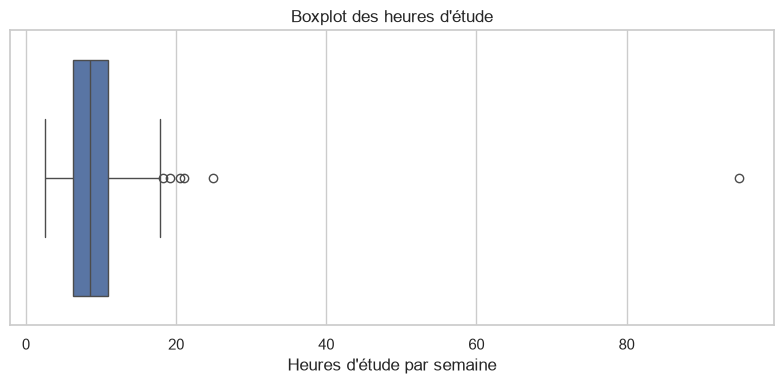

In [10]:
print("\nStatistiques de heures_etude :")
print(df["heures_etude"].describe())

Q1 = df["heures_etude"].quantile(0.25)
Q3 = df["heures_etude"].quantile(0.75)

IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["heures_etude"] < lower) |
    (df["heures_etude"] > upper)
]

print("\nLimite inférieure :", lower)
print("Limite supérieure :", upper)
print("\nValeurs aberrantes :")
print(outliers[["id", "heures_etude"]])

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["heures_etude"])
plt.title("Boxplot des heures d'étude")
plt.xlabel("Heures d'étude par semaine")
plt.tight_layout()
plt.savefig(
    r"..\results\boxplot_heures_etude.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Exclure l'observation ID = 18 de l'analyse de régression, sans modifier sa valeur originale dans le dataset.

# 0.3 - construire le tableau d'analyse

In [14]:

# ==========================================
# TODO 0.3 : CONSTRUCTION DU TABLEAU D'ANALYSE
# ==========================================

# Variables utilisees dans le projet
variables_utilisees = [
    "filiere",
    "sexe",
    "logement",
    "assiduite",
    "moyenne_bac",
    "heures_etude",
    "heures_sommeil",
    "note_stat",
    "reussite"
]

# Construction du tableau sans valeurs manquantes
d = df.dropna(
    subset=variables_utilisees
).copy()

# Verification
print("\nDimensions du tableau initial :", df.shape)
print("Dimensions du tableau d'analyse :", d.shape)

print("\nValeurs manquantes dans d :")
print(d[variables_utilisees].isnull().sum())

print("\nNombre d'observations supprimees :",
      len(df) - len(d))

# Verification finale
assert d[variables_utilisees].isnull().sum().sum() == 0

print("\nTableau d'analyse construit avec succes.")



Dimensions du tableau initial : (300, 10)
Dimensions du tableau d'analyse : (290, 10)

Valeurs manquantes dans d :
filiere           0
sexe              0
logement          0
assiduite         0
moyenne_bac       0
heures_etude      0
heures_sommeil    0
note_stat         0
reussite          0
dtype: int64

Nombre d'observations supprimees : 10

Tableau d'analyse construit avec succes.
